# A* Path Planning

This notebook introduces basic path planning using the A* search
algorithm.

The experiment represents the environment as a two-dimensional
occupancy grid containing free cells and obstacles.

The planning problem is defined by:

- A start position
- A goal position
- A set of obstacle cells
- A search space represented by a grid

The A* algorithm searches for a path from the start position to the
goal while avoiding occupied cells.

The notebook also introduces the distinction between global and local
planning.

In [1]:
# 1-14D — Environment and Library Setup

import heapq
import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)

NumPy version: 2.4.6


## Environment Representation

A simple occupancy grid is used to represent the environment.

Each grid cell has one of two states:

- `0` → free space
- `1` → obstacle

The grid provides a discrete representation of the environment in
which the planner can search for a feasible path.

In [2]:
# 2-14D — Create the Planning Grid

grid = np.zeros((15, 20), dtype=int)

# Create obstacle regions
grid[3:12, 8] = 1
grid[3, 8:15] = 1
grid[11, 8:15] = 1

start = (1, 2)
goal = (13, 17)

print("Grid shape:", grid.shape)
print("Start:", start)
print("Goal:", goal)
print("Number of obstacle cells:", np.sum(grid))

Grid shape: (15, 20)
Start: (1, 2)
Goal: (13, 17)
Number of obstacle cells: 21


## Visualize the Environment

Before running the planner, the occupancy grid is visualized to verify
the start position, goal position, and obstacle layout.

The planner should find a path through the free cells without crossing
the obstacle regions.

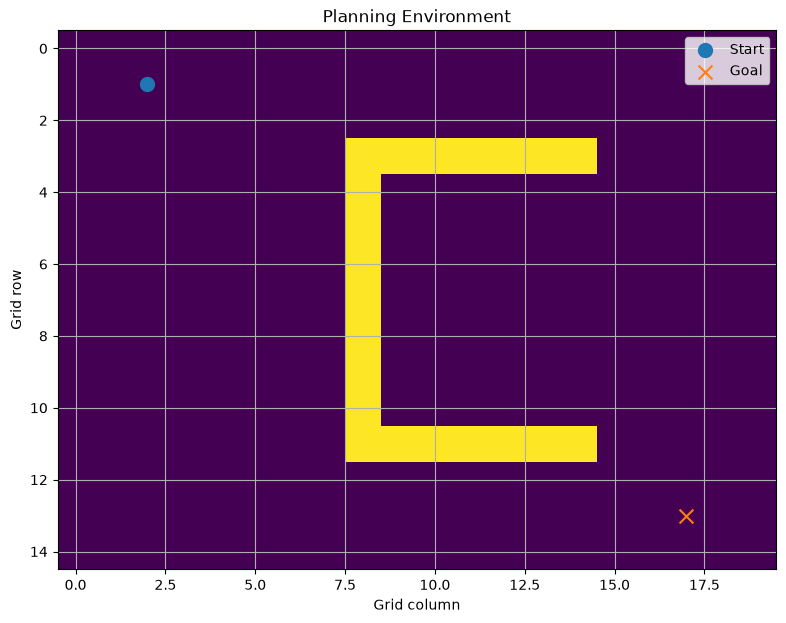

In [3]:
# 3-14D — Visualize the Planning Environment

plt.figure(figsize=(10, 7))

plt.imshow(grid, origin="upper")

plt.scatter(
    start[1],
    start[0],
    marker="o",
    s=100,
    label="Start"
)

plt.scatter(
    goal[1],
    goal[0],
    marker="x",
    s=100,
    label="Goal"
)

plt.xlabel("Grid column")
plt.ylabel("Grid row")
plt.title("Planning Environment")
plt.grid(True)
plt.legend()
plt.show()

## A* Search

A* is a graph-search algorithm that combines:

- The cost already travelled from the start node
- An estimated cost from the current node to the goal

The evaluation function is:

`f(n) = g(n) + h(n)`

where:

- `g(n)` is the accumulated path cost from the start
- `h(n)` is the heuristic estimate of the remaining cost
- `f(n)` is the estimated total cost of a path through node `n`

For this four-connected grid, the Manhattan distance is used as the
heuristic:

`h(n) = |x_n - x_goal| + |y_n - y_goal|`

The heuristic estimates the minimum number of horizontal and vertical
moves required to reach the goal when diagonal movement is not allowed.

In [4]:
# 4-14D — Define A* Helper Functions

def heuristic(node, goal):
    """Manhattan-distance heuristic."""
    return abs(node[0] - goal[0]) + abs(node[1] - goal[1])


def get_neighbors(node, grid):
    """Return valid four-connected neighboring cells."""
    row, col = node

    candidates = [
        (row - 1, col),
        (row + 1, col),
        (row, col - 1),
        (row, col + 1)
    ]

    neighbors = []

    for next_row, next_col in candidates:
        if (
            0 <= next_row < grid.shape[0]
            and 0 <= next_col < grid.shape[1]
            and grid[next_row, next_col] == 0
        ):
            neighbors.append((next_row, next_col))

    return neighbors

## Implement the A* Planner

The A* planner maintains:

- An open set containing nodes that still need to be evaluated
- A cost value `g(n)` for the best known path to each node
- A parent relationship used to reconstruct the final path

The node with the lowest estimated total cost `f(n)` is selected for
expansion.

The search continues until the goal is reached or no feasible node
remains.

In [5]:
# 5-14D — Implement A* Path Planning

def astar(grid, start, goal):
    if grid[start] == 1:
        raise ValueError("Start position is occupied by an obstacle.")

    if grid[goal] == 1:
        raise ValueError("Goal position is occupied by an obstacle.")

    open_set = []

    start_cost = heuristic(start, goal)

    heapq.heappush(
        open_set,
        (start_cost, 0, start)
    )

    came_from = {}
    g_cost = {start: 0}

    while open_set:
        _, current_g, current = heapq.heappop(open_set)

        # Ignore outdated entries in the priority queue
        if current_g != g_cost[current]:
            continue

        if current == goal:
            path = [current]

            while current in came_from:
                current = came_from[current]
                path.append(current)

            path.reverse()
            return path

        for neighbor in get_neighbors(current, grid):
            tentative_g = g_cost[current] + 1

            if (
                neighbor not in g_cost
                or tentative_g < g_cost[neighbor]
            ):
                came_from[neighbor] = current
                g_cost[neighbor] = tentative_g

                f_cost = (
                    tentative_g
                    + heuristic(neighbor, goal)
                )

                heapq.heappush(
                    open_set,
                    (f_cost, tentative_g, neighbor)
                )

    return None

## Generate the Planned Path

The A* algorithm is now executed using the defined occupancy grid,
start position, and goal position.

If a path exists, the sequence of grid cells represents the planned
route through free space.

In [6]:
# 6-14D — Generate the A* Path

path = astar(
    grid,
    start,
    goal
)

if path is None:
    print("No feasible path was found.")
else:
    print("Path found.")
    print("Number of cells in path:", len(path))
    print("Path:")
    print(path)

Path found.
Number of cells in path: 28
Path:
[(1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 10), (1, 11), (1, 12), (1, 13), (1, 14), (1, 15), (1, 16), (1, 17), (2, 17), (3, 17), (4, 17), (5, 17), (6, 17), (7, 17), (8, 17), (9, 17), (10, 17), (11, 17), (12, 17), (13, 17)]


## Visualize the Planned Path

The generated path is overlaid on the occupancy grid.

A valid path should:

- Start at the defined start position
- End at the goal position
- Remain within the grid
- Avoid obstacle cells

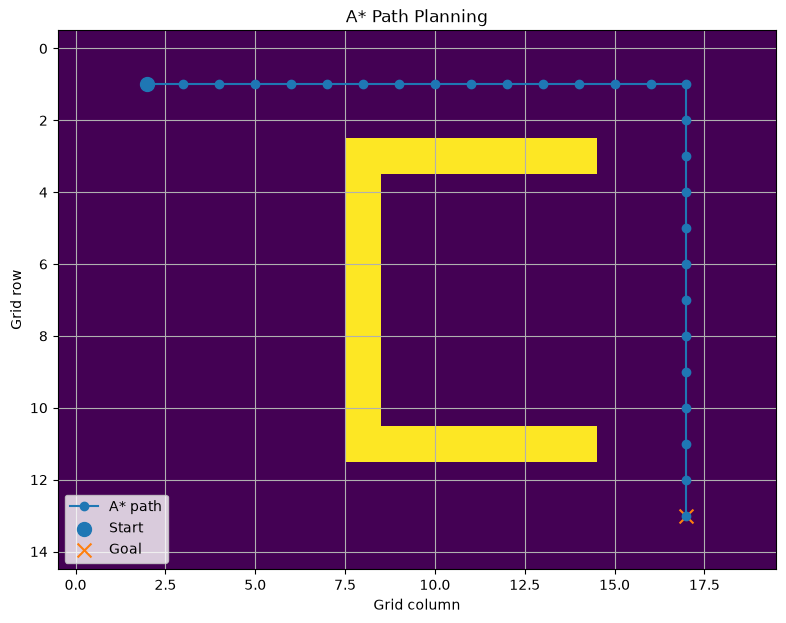

In [7]:
# 7-14D — Visualize the A* Path

plt.figure(figsize=(10, 7))

plt.imshow(grid, origin="upper")

if path is not None:
    path_array = np.array(path)

    plt.plot(
        path_array[:, 1],
        path_array[:, 0],
        marker="o",
        label="A* path"
    )

plt.scatter(
    start[1],
    start[0],
    marker="o",
    s=100,
    label="Start"
)

plt.scatter(
    goal[1],
    goal[0],
    marker="x",
    s=100,
    label="Goal"
)

plt.xlabel("Grid column")
plt.ylabel("Grid row")
plt.title("A* Path Planning")
plt.grid(True)
plt.legend()
plt.show()

## Path Validation

The planned path can be checked to verify that every path cell is
inside the grid and corresponds to free space.

This provides a basic validity check for the generated path.

In [8]:
# 8-14D — Validate the Planned Path

if path is None:
    print("Path validation failed: no path was generated.")
else:
    path_is_valid = True

    for cell in path:
        row, col = cell

        if (
            row < 0
            or row >= grid.shape[0]
            or col < 0
            or col >= grid.shape[1]
            or grid[row, col] == 1
        ):
            path_is_valid = False
            break

    print("Path starts at start position:", path[0] == start)
    print("Path ends at goal position:", path[-1] == goal)
    print("Path avoids obstacles:", path_is_valid)

Path starts at start position: True
Path ends at goal position: True
Path avoids obstacles: True


## Global and Local Planning

Global and local planning operate at different levels.

### Global Planning

A global planner uses a larger representation of the environment to
determine a route from the current position toward a destination.

A* is an example of a global path-planning algorithm when applied to
an occupancy grid representing the environment.

### Local Planning

A local planner operates over a limited region around the vehicle and
reacts to nearby obstacles, vehicle motion, and changing conditions.

The local planner can modify or select a short section of the route
while the global planner provides the overall navigation objective.

The two approaches are therefore complementary:

`Global planner → overall route`

`Local planner → short-term motion and obstacle avoidance`

## Limitations

This A* experiment uses a discrete two-dimensional grid and therefore
does not represent a complete automotive motion-planning system.

The implementation assumes:

- A known occupancy grid
- Static obstacles
- Four-connected grid movement
- Unit movement cost
- A known start position
- A known goal position
- No vehicle dimensions
- No vehicle dynamics or kinematic constraints
- No uncertainty in the environment

The generated path is therefore a geometric grid path rather than a
directly executable vehicle trajectory.

Further planning stages can introduce path smoothing, vehicle
constraints, local obstacle avoidance, and more realistic planning
representations.

## Conclusion

The experiment demonstrated the basic path-planning workflow using the
A* search algorithm.

An occupancy grid was used to represent the environment, while the
start and goal positions defined the planning problem. A* combined
the accumulated path cost and a heuristic estimate of the remaining
cost to search for a feasible path.

The resulting path avoided the defined obstacle cells and connected
the start position to the goal position.

The experiment also established the distinction between global and
local planning. A global planner can determine an overall route,
while a local planner can react to nearby obstacles and changing
conditions.

The implementation provides a minimal foundation for subsequent work
on path smoothing and local planning.